# Mini-modèle ALM fonds euros : V4, le passif « à la Prophet »

Les versions 1 à 3 projettent le fonds avec une boucle Python écrite à la main. Un outil de modélisation actuarielle comme Prophet s'organise autrement :

| Prophet | Ici |
| --- | --- |
| Fichier de model points | `data/v4/model_points.csv` |
| Tables d'hypothèses | `data/v4/table_mortalite.csv`, `table_rachats.csv`, `parametres.json` |
| Bibliothèque de variables, une formule par variable écrite en t | `src/prophet/epargne.py` |
| Moteur qui déduit l'ordre de calcul des appels entre variables | `src/prophet/moteur.py` |
| Taux servi reçu de l'ALS (module actif-passif) | scénario issu des projections de la V1 |
| Résultats par model point et par année | tableau long, un model point par ligne et par année |

Ce qu'on y gagne : une hypothèse se change dans une table sans toucher au code, une variable se lit isolément, et le moteur interdit les dépendances circulaires.

In [1]:
import os, subprocess, sys
if not os.path.exists("src"):
    if os.path.basename(os.getcwd()) == "notebooks":
        os.chdir("..")
    else:
        if not os.path.exists("mini-alm-fonds-euros"):
            subprocess.run(["git", "clone", "https://github.com/TorjmenYou/mini-alm-fonds-euros.git"], check=True)
        os.chdir("mini-alm-fonds-euros")
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.hypotheses import charger_hypotheses
h = charger_hypotheses()

BLEU, ORANGE, VERT, JAUNE = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
ENCRE, ENCRE_2, GRILLE, FOND = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FOND, "axes.facecolor": FOND, "axes.edgecolor": GRILLE,
    "axes.labelcolor": ENCRE_2, "xtick.color": ENCRE_2, "ytick.color": ENCRE_2,
    "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})
pd.set_option("display.precision", 4)

def titre(ax, texte):
    ax.set_title(texte, loc="left", color=ENCRE, fontsize=11)

## 1. Une variable, c'est une formule en t

Extrait de la bibliothèque : la PM de fin d'année et la valeur actuelle des sorties, calculée par récurrence vers l'arrière.

```python
@v("PM_FIN", "PM en fin d'année t")
def _(m, t):
    if t == 0:
        return m.colonne("pm")
    return m("PM_REVAL", t) - m("PRESTATIONS", t)


@v("VA_SORTIES", "Valeur à la date t des prestations et frais futurs, plus la PM rendue à l'horizon")
def _(m, t):
    if t == m.T:
        return m("PM_FIN", t)
    flux = m("PRESTATIONS", t + 1) + m("FRAIS", t + 1) + m("VA_SORTIES", t + 1)
    return flux / (1 + m("TAUX_ACTU", t + 1))
```

Chaque appel `m("NOM", t)` renvoie un vecteur, une valeur par model point. Le moteur le calcule une seule fois et note la dépendance.

In [2]:
from src.projection import projeter, scenario
from src.prophet.tables import charger, scenario_depuis_projection, DOSSIER
from src.prophet.epargne import construire

noms = {"central": "Central", "hausse_taux_200pb": "Taux +200 pb", "baisse_taux_100pb": "Taux -100 pb"}
scenarios = {nom: scenario_depuis_projection(projeter(h, scenario(h, nom)), h) for nom in noms}
modele = construire(scenarios["central"])
resultats = {"central": modele.calculer()}
modele.arbre_des_variables()

,description,appelle
variable,,
AGE,Âge atteint à la date t,
ANCIENNETE,Ancienneté atteinte à la date t,
TMG,Taux minimum garanti du contrat,
QX,"Probabilité de décès dans l'année t, à l'âge d...",AGE
TX_RACHAT_STRUCT,"Taux de rachat structurel, selon l'ancienneté ...",ANCIENNETE
TAUX_FONDS,Taux servi par le fonds l'année t (scénario),
TAUX_ATTENDU,Taux attendu par les assurés l'année t (scénario),
TAUX_ACTU,Taux d'actualisation de l'année t (scénario),
TAUX_SERVI,"Taux crédité au contrat : taux du fonds, au mo...","TAUX_FONDS, TMG"


Lecture : c'est l'« arbre des variables ». Il se lit de bas en haut, du résultat vers ses sources : `VA_SORTIES` appelle les prestations et les frais, qui appellent la PM revalorisée, qui appelle le taux servi, et ainsi de suite jusqu'aux tables et aux model points. Personne n'a écrit l'ordre de calcul : il découle de ces appels.

## 2. Les model points et les tables

In [3]:
mp, tables, param = charger()
mp

,id,produit,age,anciennete,nb_contrats,pm,tmg
0,1,Épargne individuelle,35,2,4000,150.0,0.000
1,2,Épargne individuelle,45,6,3500,200.0,0.000
2,3,Épargne individuelle,55,9,3000,220.0,0.000
3,4,Épargne individuelle,68,15,2000,180.0,0.010
4,5,Épargne individuelle,75,25,1000,100.0,0.025
5,6,Retraite collective,50,10,500,150.0,0.000


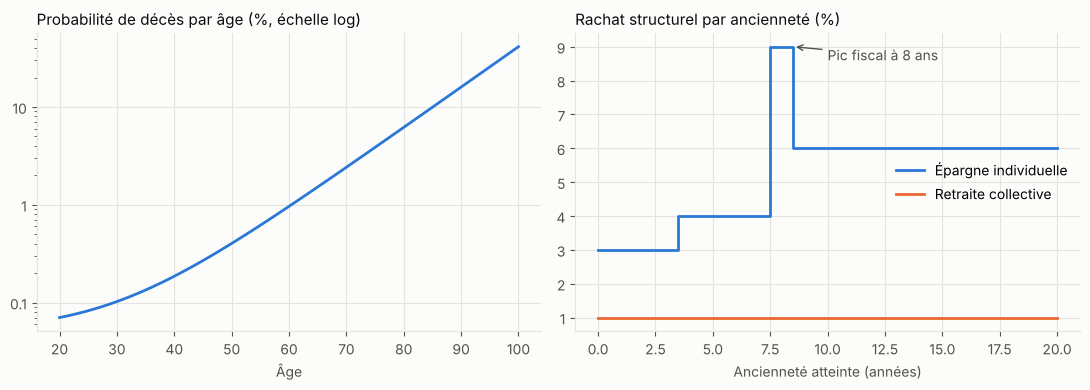

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
mort = tables["mortalite"].df["qx"]
ax.plot(mort.index[20:101], mort.loc[20:100] * 100, color=BLEU, linewidth=2)
ax.set_yscale("log")
from matplotlib.ticker import FuncFormatter
ax.yaxis.set_major_formatter(FuncFormatter(lambda val, _: f"{val:g}"))
titre(ax, "Probabilité de décès par âge (%, échelle log)")
ax.set_xlabel("Âge")

ax = axes[1]
rach = tables["rachats"].df
for produit, couleur in zip(rach.columns, [BLEU, ORANGE]):
    ax.step(rach.index[:21], rach[produit].iloc[:21] * 100, where="mid", color=couleur, linewidth=2, label=produit)
titre(ax, "Rachat structurel par ancienneté (%)")
ax.set_xlabel("Ancienneté atteinte (années)")
ax.annotate("Pic fiscal à 8 ans", xy=(8.5, 9), xytext=(10, 8.6), color=ENCRE_2, arrowprops=dict(arrowstyle="->", color=ENCRE_2))
ax.legend(frameon=False, loc="center right")
fig.tight_layout()
fig.savefig("figures/tables_v4.png", dpi=150, bbox_inches="tight")
plt.show()

Lecture :
- **Six model points**, pour 1 000 M€ de PM : cinq générations d'épargne individuelle et un contrat de retraite collective. Les contrats les plus anciens portent un TMG (1 % et 2,5 %), comme les contrats souscrits quand les taux étaient élevés.
- **Mortalité** : une table fictive de type Gompertz-Makeham, pas une table réglementaire.
- **Rachats en épargne** : ils montent avec l'ancienneté, avec un pic à 8 ans, quand la fiscalité de l'assurance vie devient favorable. En retraite collective, l'épargne est bloquée jusqu'à la retraite, et les sorties restent faibles.

## 3. Validation : la V4 retrouve exactement la V1

Avec un jeu de tables de validation (un seul model point, mortalité de 1 % et rachat de 5 % à tout âge), le passif de la V4 doit reproduire celui de la V1, au centime près. C'est ainsi qu'on valide une réécriture de modèle : on compare l'ancien et le nouveau sur un cas où ils doivent coïncider.

In [5]:
lignes = []
for nom, sc in scenarios.items():
    df = projeter(h, scenario(h, nom))
    r = construire(sc, DOSSIER / "validation").calculer()
    d = df["deflateur"]
    va_v1 = ((df["prestations"] + df["frais"]) * d).sum() + df["pm"].iloc[-1] * d.iloc[-1]
    lignes.append({
        "Scénario": noms[nom],
        "Écart max sur la PM": abs(r["PM_FIN"].to_numpy() - df["pm"].to_numpy()).max(),
        "Écart max sur les prestations": abs(r["PRESTATIONS"].to_numpy() - df["prestations"].to_numpy()).max(),
        "Valeur actuelle des sorties, V1": va_v1,
        "Valeur actuelle des sorties, V4": r["VA_SORTIES"].iloc[0],
    })
pd.DataFrame(lignes).set_index("Scénario")

,Écart max sur la PM,Écart max sur les prestations,"Valeur actuelle des sorties, V1","Valeur actuelle des sorties, V4"
Scénario,,,,
Central,1.1369e-13,7.1054e-15,966.7321,966.7321
Taux +200 pb,1.1369e-13,2.8422e-14,932.0514,932.0514
Taux -100 pb,2.2737e-13,2.1316e-14,981.0309,981.0309


Lecture : les écarts sont de l'ordre de 10⁻¹³, c'est-à-dire de simples arrondis de calcul. La réécriture est fidèle.

## 4. Le portefeuille de model points sous trois scénarios

Le taux servi par le fonds vient des projections actif-passif de la V1 : c'est le rôle que joue l'ALS dans Prophet. Chaque contrat reçoit le taux du fonds, et au moins son TMG.

In [6]:
for nom, sc in scenarios.items():
    if nom not in resultats:
        resultats[nom] = construire(sc).calculer()

synthese = []
for nom, r in resultats.items():
    t0 = r.xs(0, level="annee").join(mp.set_index("id")["produit"])
    for produit, g in t0.groupby("produit"):
        synthese.append({"Scénario": noms[nom], "Produit": produit,
                         "PM initiale": g["PM_FIN"].sum(),
                         "Valeur actuelle des sorties": g["VA_SORTIES"].sum(),
                         "dont coût des TMG": g["VA_COUT_TMG"].sum()})
pd.DataFrame(synthese).set_index(["Scénario", "Produit"]).round(1)

PM initiale  Valeur actuelle des sorties  \
Scénario     Produit                                                          
Central      Retraite collective         150.0                        140.1   
             Épargne individuelle        850.0                        830.3   
Taux +200 pb Retraite collective         150.0                        136.6   
             Épargne individuelle        850.0                        796.1   
Taux -100 pb Retraite collective         150.0                        144.1   
             Épargne individuelle        850.0                        847.4   

                                   dont coût des TMG  
Scénario     Produit                                  
Central      Retraite collective                 0.0  
             Épargne individuelle                0.5  
Taux +200 pb Retraite collective                 0.0  
             Épargne individuelle                0.4  
Taux -100 pb Retraite collective                 0.0  
             Épargne individuelle                7.9

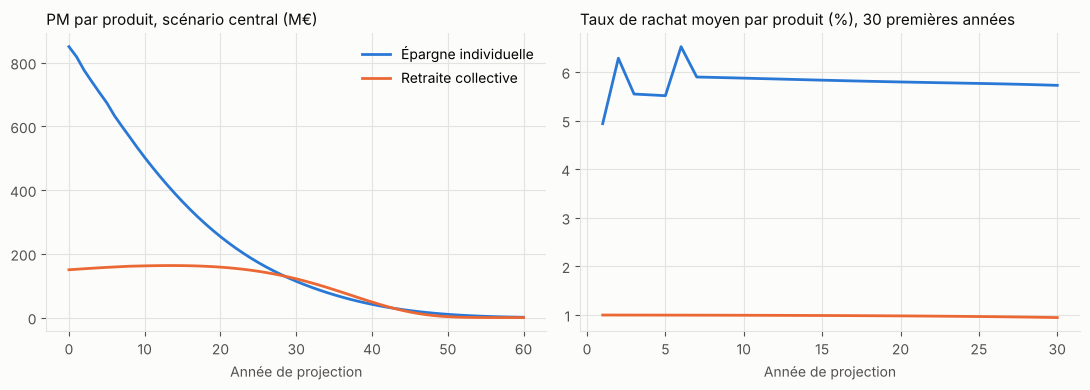

In [7]:
r = resultats["central"].join(mp.set_index("id")["produit"], on="model_point")
par_produit = r.groupby(["produit", "annee"])[["PM_FIN", "RACHATS", "PM_REVAL"]].sum()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for produit, couleur in zip(["Épargne individuelle", "Retraite collective"], [BLEU, ORANGE]):
    g = par_produit.loc[produit]
    axes[0].plot(g.index, g["PM_FIN"], color=couleur, linewidth=2, label=produit)
    taux = (g["RACHATS"] / g["PM_REVAL"]).where(g["PM_REVAL"] > 0)
    axes[1].plot(taux.index[1:31], taux.iloc[1:31] * 100, color=couleur, linewidth=2, label=produit)
titre(axes[0], "PM par produit, scénario central (M€)")
titre(axes[1], "Taux de rachat moyen par produit (%), 30 premières années")
for ax in axes:
    ax.set_xlabel("Année de projection")
axes[0].legend(frameon=False, loc="upper right")
fig.tight_layout()
fig.savefig("figures/portefeuille_v4.png", dpi=150, bbox_inches="tight")
plt.show()

Lecture :
- **Rachats** : le taux moyen de l'épargne individuelle bouge au rythme des générations. Il monte quand une génération atteint 8 ans d'ancienneté (l'année 2 pour le model point de 6 ans, l'année 6 pour celui de 2 ans), puis se stabilise vers 6 %. Avec une seule hypothèse plate, comme en V1, ces effets disparaissent.
- **Retraite collective** : la PM s'écoule lentement, car les sorties se limitent aux décès et à 1 % de transferts.
- **Coût des TMG** : il apparaît dès que le taux du fonds passe sous un TMG. Il est faible dans le scénario central (le fonds sert environ 2,3 % pour un TMG de 2,5 % sur un seul model point) et nettement plus élevé quand les taux baissent de 100 pb (taux du fonds de 1,5 % les dix premières années, puis environ 1,3 %). C'est le type de chiffre qu'un modèle Prophet sort par génération de contrats.

## 5. Le moteur refuse les dépendances circulaires

Deux variables qui s'appellent l'une l'autre à la même date n'ont pas de solution. Prophet refuse de compiler un tel modèle. Ici, le moteur le détecte au calcul et indique la chaîne fautive.

In [8]:
from src.prophet.moteur import Bibliotheque, DependanceCirculaire, Modele

bib = Bibliotheque()

@bib.variable("TAUX_SERVI", "dépend des rachats de l'année")
def _(m, t):
    return 0.02 - 0.1 * m("TX_RACHAT", t)

@bib.variable("TX_RACHAT", "dépend du taux servi de l'année")
def _(m, t):
    return 0.05 + 0.5 * (0.03 - m("TAUX_SERVI", t))

try:
    Modele(bib, mp, tables, param, scenarios["central"])("TAUX_SERVI", 1)
except DependanceCirculaire as erreur:
    print("Dépendance circulaire :", erreur)

Dépendance circulaire : TAUX_SERVI(1) -> TX_RACHAT(1) -> TAUX_SERVI(1)


C'est exactement la circularité que la V1 évite en faisant dépendre les rachats de l'année t du taux servi de l'année t-1.

## Limites de la V4
- Seul le passif est réécrit à la Prophet. Le taux servi vient des projections de la V1, comme d'un ALS, sans rétroaction des rachats du portefeuille sur l'actif.
- Pas de pas mensuel, pas de regroupement automatique des contrats en model points, pas de lecture de fichiers de scénarios stochastiques.
- Table de mortalité fictive et hypothèses de rachat illustratives.